# Logistic regression : gradient ascent, Newton, frontière de décision

Carnet CS229, bloc **B14**, étape 10 · **version à trous**

---

## Ce que vous allez construire

Tout, à la main. Pas un seul appel à `sklearn.linear_model.LogisticRegression`.

$$g(z) = \frac{1}{1+e^{-z}} \qquad
\ell(\theta) = \sum_{i=1}^{n}\Bigl[y^{(i)}\log h_{\theta}(x^{(i)}) + \bigl(1-y^{(i)}\bigr)\log\bigl(1-h_{\theta}(x^{(i)})\bigr)\Bigr]$$

$$\nabla_{\theta}\,\ell(\theta) = X^{\top}(y - h) \qquad
H = -X^{\top}\operatorname{diag}\bigl(h\odot(1-h)\bigr)X$$

puis les deux façons de monter vers le maximum :

$$\textbf{gradient ascent}:\; \theta := \theta + \alpha\,\nabla_{\theta}\ell(\theta)
\qquad\qquad
\textbf{Newton}:\; \theta := \theta - H^{-1}\,\nabla_{\theta}\ell(\theta)$$

## Pourquoi cet exercice compte

C'est le **seul endroit du parcours** où vous implémentez Newton à la main. Ailleurs, les
bibliothèques le font pour vous et la méthode reste une formule abstraite. Ici vous verrez
le nombre de décimales exactes **doubler à chaque itération**, ce qu'aucune explication ne
remplace.

Vous verrez aussi, mesuré sur vos propres données, pourquoi le gradient ascent met des
milliers d'itérations là où Newton en met sept.

## Mode d'emploi

Les cellules marquées `# TODO` contiennent des `...` à remplacer. Chacune est suivie d'une
**cellule de vérification** qui s'exécute seule et vous dit si c'est juste.

**9 trous.** Comptez 2 h 30. Aucun téléchargement : les données sont générées.

## Notation

Carnet et CS229 : $n$ exemples, $d$ features. Ici $n = 100$, $d = 2$, et
$X \in \mathbb{R}^{100 \times 3}$ après ajout de la colonne de biais. Hands-On ML écrirait
$m$ exemples et $n$ features.

**On maximise** $\ell(\theta)$, d'où « ascent ». Beaucoup de textes minimisent
$J(\theta) = -\ell(\theta)$ et écrivent donc les mises à jour avec les signes inversés.

---
## 1. Environnement

*Cellule complète.*

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt

# Définition de la graine aléatoire pour la reproductibilité
SEED = 42
plt.rcParams["figure.dpi"] = 110

print("numpy", np.__version__)

numpy 2.3.5


---
## 2. Les données

Deux nuages gaussiens en dimension 2, qui **se chevauchent légèrement**.

Ce chevauchement n'est pas un détail de confort : avec des classes **parfaitement
séparables**, le maximum de vraisemblance **n'existe pas**. On peut toujours augmenter
$\ell(\theta)$ en multipliant $\theta$ par une constante plus grande, donc
$\lVert\theta\rVert \to \infty$ et l'algorithme ne s'arrête jamais. La section 11 vous le
fera constater.

*Cellule complète.*

In [ ]:
# Génération de données aléatoires pour la classification binaire
def genere_donnees(n=100, seed=SEED):
    rng = np.random.default_rng(seed)
    n0, n1 = n // 2, n - n // 2
    X0 = rng.multivariate_normal([1.0, 1.0], [[1.0, 0.3], [0.3, 1.0]], n0)
    X1 = rng.multivariate_normal([3.2, 3.0], [[1.0, 0.3], [0.3, 1.0]], n1)
    X_raw = np.vstack([X0, X1])
    y = np.concatenate([np.zeros(n0), np.ones(n1)])
    perm = rng.permutation(n)
    return X_raw[perm], y[perm]

# Génération des données
X_raw, y = genere_donnees()
print("X_raw :", X_raw.shape, " y :", y.shape)
print("classes :", np.bincount(y.astype(int)))

X_raw : (100, 2)  y : (100,)
classes : [50 50]


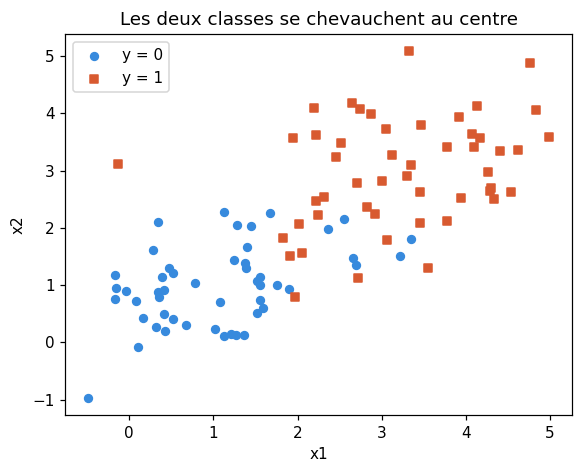

In [3]:
fig, ax = plt.subplots(figsize=(5.4, 4.4))
ax.scatter(X_raw[y == 0, 0], X_raw[y == 0, 1], c="#378ADD", s=26, label="y = 0")
ax.scatter(X_raw[y == 1, 0], X_raw[y == 1, 1], c="#D85A30", s=26, marker="s", label="y = 1")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend()
ax.set_title("Les deux classes se chevauchent au centre")
plt.tight_layout(); plt.show()

### Trou 1 — la colonne de biais

Le modèle s'écrit $h_{\theta}(x) = g(\theta^{\top}x)$ avec

$$\theta = \begin{pmatrix}\theta_{0}\\ \theta_{1}\\ \theta_{2}\end{pmatrix} \in \mathbb{R}^{3},
\qquad
x = \begin{pmatrix}1\\ x_{1}\\ x_{2}\end{pmatrix} \in \mathbb{R}^{3}$$

Le $1$ en tête est ce qui donne à $\theta_{0}$ le rôle d'ordonnée à l'origine : sans lui, la
frontière passerait forcément par l'origine. C'est la **convention d'intercept** du point
**B11-2**.

Il faut donc passer de $X_{\text{raw}} \in \mathbb{R}^{n \times d}$ à
$X \in \mathbb{R}^{n \times (d+1)}$.

In [4]:
# TODO (trou 1) - Ajouter une colonne de 1 EN PREMIERE POSITION.
#   Entree : X_raw de forme (n, d)
#   Sortie : (n, d+1), la colonne 0 ne contenant que des 1
#   Indice : np.ones((n, 1)) puis np.hstack([...]) pour concatener horizontalement

def ajoute_biais(X_raw):
    n, d = X_raw.shape
    return np.hstack([np.ones((n, 1)), X_raw])

X = ajoute_biais(X_raw)
print("X :", X.shape)
print("3 premieres lignes :\n", X[:3].round(3))    # <-- a completer

X : (100, 3)
3 premieres lignes :
 [[1.    4.167 3.565]
 [1.    1.917 1.504]
 [1.    3.455 2.629]]


In [5]:
# Verification - ne modifiez pas cette cellule
assert X.shape == (100, 3), f"X devrait etre (100, 3), pas {X.shape}"
assert np.all(X[:, 0] == 1.0), "la colonne 0 doit etre remplie de 1"
assert np.array_equal(X[:, 1:], X_raw), "les colonnes 1 et 2 doivent reprendre X_raw a l'identique"

_t = ajoute_biais(np.array([[5.0, 7.0]]))
assert np.array_equal(_t, np.array([[1.0, 5.0, 7.0]])), \
    "le 1 va DEVANT les features, pas derriere"
print("Trou 1 : OK")

Trou 1 : OK


---
## 3. La sigmoïde

$$g(z) = \frac{1}{1 + e^{-z}}$$

### Trou 2 — version naïve, puis le problème

Écrivez d'abord la formule telle quelle. On regardera ensuite où elle casse.

In [6]:
# TODO (trou 2) - Ecrire la sigmoide, formule directe.
#   z est un tableau NumPy ; la fonction doit marcher element par element.
#   Indice : np.exp

def sigmoid_naive(z):
    return 1/(1+np.exp(-z))        # <-- a completer

In [7]:
# Verification - ne modifiez pas cette cellule
assert abs(sigmoid_naive(np.array([0.0]))[0] - 0.5) < 1e-12, "g(0) doit valoir exactement 0.5"
assert sigmoid_naive(np.array([10.0]))[0] > 0.999, "g(+10) doit etre proche de 1"
assert sigmoid_naive(np.array([-10.0]))[0] < 0.001, "g(-10) doit etre proche de 0"

_z = np.array([-2.0, 0.0, 2.0])
assert np.allclose(sigmoid_naive(_z) + sigmoid_naive(-_z), 1.0), \
    "symetrie attendue : g(-z) = 1 - g(z)"
print("Trou 2 : OK")

Trou 2 : OK


### Le problème que la formule directe ne voit pas venir

Exécutez la cellule suivante.

In [8]:
import warnings
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    val = sigmoid_naive(np.array([-800.0]))
    print("g(-800) =", val[0])
    for x in w:
        print("AVERTISSEMENT :", x.message)

g(-800) = 0.0
AVERTISSEMENT : overflow encountered in exp


Pour $z = -800$, le calcul passe par $e^{800}$, qui dépasse le plus grand `float64`
représentable (environ $1{,}8 \times 10^{308}$). NumPy renvoie `inf`, puis $1/\infty = 0$.

Le résultat **numérique** est juste — $g(-800)$ vaut bien 0 à la précision machine — mais
l'avertissement pollue les sorties, et dans d'autres formulations le dépassement produit des
`nan` qui se propagent silencieusement.

**La parade** : exponentier uniquement ce qui ne peut pas déborder. Pour $z \geq 0$,
$e^{-z} \leq 1$ ; pour $z < 0$, on réécrit

$$g(z) = \frac{1}{1+e^{-z}} = \frac{e^{z}}{1+e^{z}}$$

et cette fois c'est $e^{z} \leq 1$. Dans les deux branches, l'exponentielle reste bornée.

*Cellule complète — on utilise cette version pour la suite.*

In [9]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    print("g(-800) =", sigmoid(np.array([-800.0]))[0], " avertissements :", len(w))
print("identique a la version naive sur [-10, 10] :",
      np.allclose(sigmoid(np.linspace(-10, 10, 50)), sigmoid_naive(np.linspace(-10, 10, 50))))

g(-800) = 0.0  avertissements : 0
identique a la version naive sur [-10, 10] : True


### Trou 3 — la dérivée

C'est la propriété qui rend tout le reste simple :

$$g'(z) = g(z)\bigl(1 - g(z)\bigr)$$

Démonstration en trois lignes :

$$g'(z) = \frac{\mathrm{d}}{\mathrm{d}z}\left(1 + e^{-z}\right)^{-1}
= \frac{e^{-z}}{\left(1+e^{-z}\right)^{2}}
= \frac{1}{1+e^{-z}} \cdot \frac{e^{-z}}{1+e^{-z}}
= g(z)\bigl(1-g(z)\bigr)$$

**N'exponentiez rien** : appelez `sigmoid`.

In [10]:
# TODO (trou 3) - Ecrire g'(z) en reutilisant sigmoid(z).

def sigmoid_prime(z):
    return sigmoid(z)*(1-sigmoid(z))        # <-- a completer

In [11]:
# Verification - ne modifiez pas cette cellule, elle compare a des differences finies
_z = np.linspace(-6, 6, 25)
_eps = 1e-6
_num = (sigmoid(_z + _eps) - sigmoid(_z - _eps)) / (2 * _eps)
_ana = sigmoid_prime(_z)

assert np.allclose(_ana, _num, atol=1e-7), \
    "votre derivee ne correspond pas aux differences finies de sigmoid"
assert abs(sigmoid_prime(np.array([0.0]))[0] - 0.25) < 1e-12, \
    "g'(0) doit valoir exactement 0.25, le maximum de la derivee"
assert sigmoid_prime(np.array([8.0]))[0] < 1e-3, \
    "la derivee doit s'ecraser vers 0 dans les queues"
print("Trou 3 : OK  (derivee validee par differences finies)")

Trou 3 : OK  (derivee validee par differences finies)


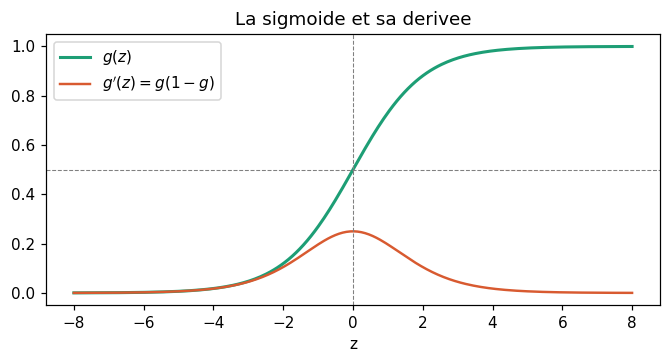

In [12]:
z = np.linspace(-8, 8, 300)
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.plot(z, sigmoid(z), color="#1D9E75", lw=2, label=r"$g(z)$")
ax.plot(z, sigmoid_prime(z), color="#D85A30", lw=1.6, label=r"$g'(z) = g(1-g)$")
ax.axhline(0.5, color="gray", ls="--", lw=0.7)
ax.axvline(0.0, color="gray", ls="--", lw=0.7)
ax.set_xlabel("z"); ax.legend(); ax.set_title("La sigmoide et sa derivee")
plt.tight_layout(); plt.show()

Notez l'écrasement de $g'$ dans les queues : au-delà de $|z| = 6$, la dérivée est
pratiquement nulle. C'est le **vanishing gradient**, que vous retrouverez en phase 2 du
carnet comme la raison pour laquelle les réseaux profonds ont abandonné la sigmoïde au
profit de ReLU.

---
## 4. La log-vraisemblance

$$\ell(\theta) = \sum_{i=1}^{n}\Bigl[y^{(i)}\log h_{\theta}(x^{(i)})
+ \bigl(1-y^{(i)}\bigr)\log\bigl(1-h_{\theta}(x^{(i)})\bigr)\Bigr]$$

Rappel de sa provenance (point **B14-3**) : on suppose
$y^{(i)} \mid x^{(i)};\theta \sim \mathrm{Bernoulli}\bigl(h_{\theta}(x^{(i)})\bigr)$, on
écrit la vraisemblance du jeu complet comme un **produit**, et on prend le logarithme pour
le transformer en somme.

### Trou 4

Écrivez la formule directement. Le piège numérique est traité juste après.

In [13]:
# TODO (trou 4) - Calculer l(theta). La fonction renvoie un SCALAIRE (un float).
#   Etapes : z = X @ theta, puis h = sigmoid(z), puis la somme de la formule.
#   Indice : np.log, np.sum. Pensez a float(...) pour la sortie.

def log_vraisemblance_naive(theta, X, y):
    z = X@theta
    h = sigmoid(z)
    l_theta = y*np.log(h)+(1-y)*np.log(1-h)
    return float(np.sum(l_theta))        # <-- a completer

In [14]:
# Verification - ne modifiez pas cette cellule
_l0 = log_vraisemblance_naive(np.zeros(3), X, y)
_attendu = 100 * np.log(0.5)
assert isinstance(_l0, float), "la fonction doit renvoyer un float, pas un tableau"
assert abs(_l0 - _attendu) < 1e-9, \
    f"en theta=0 toutes les probas valent 0.5, donc l = 100*log(0.5) = {_attendu:.4f}"
assert _l0 < 0, "une log-vraisemblance de Bernoulli est toujours negative"

_th = np.array([-7.1, 1.33, 2.28])
assert log_vraisemblance_naive(_th, X, y) > _l0, \
    "un bon theta doit donner une vraisemblance PLUS GRANDE que theta=0"
print(f"Trou 4 : OK   l(0) = {_l0:.4f}")

Trou 4 : OK   l(0) = -69.3147


### Pourquoi cette version va casser

$\log(0) = -\infty$. Dès qu'un $h_{\theta}(x^{(i)})$ atteint 0 ou 1 à la précision machine —
ce qui arrive dès que $|\theta^{\top}x|$ dépasse 37 environ — vous obtenez
$0 \times (-\infty) = \text{nan}$, et le `nan` contamine toute la somme.

La parade utilise l'identité

$$\log g(z) = -\log\left(1 + e^{-z}\right) \qquad\text{et}\qquad
\log\bigl(1 - g(z)\bigr) = -\log\left(1 + e^{z}\right)$$

que NumPy calcule de façon stable avec `np.logaddexp(0, x)`, lequel vaut $\log(1 + e^{x})$
sans jamais faire déborder l'exponentielle.

*Cellule complète — version utilisée pour la suite.*

In [15]:
def log_vraisemblance(theta, X, y):
    z = X @ theta
    return float(np.sum(-y * np.logaddexp(0, -z) - (1 - y) * np.logaddexp(0, z)))


_extreme = np.array([-400.0, 90.0, 150.0])
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    a = log_vraisemblance_naive(_extreme, X, y)
    b = log_vraisemblance(_extreme, X, y)
print(f"theta extreme -> version naive : {a}")
print(f"                version stable : {b:.4f}")
print("accord sur un theta raisonnable :",
      np.isclose(log_vraisemblance_naive(np.zeros(3), X, y),
                 log_vraisemblance(np.zeros(3), X, y)))

theta extreme -> version naive : nan
                version stable : -951.6963
accord sur un theta raisonnable : True


---
## 5. Le gradient

$$\nabla_{\theta}\,\ell(\theta) = \sum_{i=1}^{n}\left(y^{(i)} - h_{\theta}(x^{(i)})\right)x^{(i)}
\;=\; X^{\top}\left(y - h\right) \;\in\; \mathbb{R}^{d+1}$$

C'est le résultat remarquable du point **B14-4** : malgré la sigmoïde, on retrouve
exactement la forme **erreur $\times$ feature** de la régression linéaire. Ce n'est pas une
coïncidence — c'est la signature des modèles linéaires généralisés (bloc **B15**).

### Trou 5

Attention au **sens de la soustraction**. On maximise $\ell$, donc le gradient contient
$y - h$. Si vous écrivez $h - y$, vous obtenez le gradient de $J = -\ell$ et vous
descendrez au lieu de monter.

In [16]:
# TODO (trou 5) - Calculer le gradient. Sortie : vecteur de forme (d+1,).
#   Indice : X.T @ (quelque chose). Pas de boucle.

def gradient(theta, X, y):
    return X.T @ (y - sigmoid(X @ theta))       # <-- a completer

In [17]:
# Verification - ne modifiez pas cette cellule : GRADIENT CHECK par differences finies
def _grad_numerique(f, theta, X, y, eps=1e-6):
    g = np.zeros_like(theta)
    for j in range(len(theta)):
        e = np.zeros_like(theta); e[j] = eps
        g[j] = (f(theta + e, X, y) - f(theta - e, X, y)) / (2 * eps)
    return g


_rng = np.random.default_rng(0)
for _essai in range(3):
    _th = _rng.normal(0, 0.5, 3)
    _ana = gradient(_th, X, y)
    _num = _grad_numerique(log_vraisemblance, _th, X, y)
    _err = np.linalg.norm(_ana - _num) / max(np.linalg.norm(_num), 1e-12)
    assert _ana.shape == (3,), f"le gradient doit avoir la forme (3,), pas {_ana.shape}"
    assert _err < 1e-5, (
        f"desaccord avec les differences finies (erreur relative {_err:.2e}).\n"
        f"  analytique : {_ana}\n  numerique  : {_num}\n"
        f"  si les signes sont opposes, vous avez ecrit (h - y) au lieu de (y - h)")
print("Trou 5 : OK  (gradient valide par differences finies sur 3 theta aleatoires)")

Trou 5 : OK  (gradient valide par differences finies sur 3 theta aleatoires)


Le **gradient check** que vous venez d'exécuter est l'outil le plus utile de tout ce
notebook. Il compare votre dérivée analytique à

$$\frac{\partial \ell}{\partial \theta_{j}} \approx
\frac{\ell(\theta + \varepsilon e_{j}) - \ell(\theta - \varepsilon e_{j})}{2\varepsilon}$$

Gardez le réflexe : **toute dérivée écrite à la main se vérifie ainsi**, en trois lignes,
avant d'être utilisée. C'est comme cela qu'on débusque un signe inversé ou une transposée
oubliée, qui autrement se manifestent par « ça converge mal » sans explication.

La différence **centrée** (avec $\pm\varepsilon$) est préférable à la différence avant :
son erreur est en $O(\varepsilon^{2})$ au lieu de $O(\varepsilon)$.

---
## 6. Gradient ascent

$$\theta := \theta + \alpha\,\nabla_{\theta}\,\ell(\theta)$$

On **ajoute**, puisqu'on monte. Le critère d'arrêt porte sur la norme du gradient : au
maximum, $\nabla_{\theta}\ell = 0$.

### Trou 6

In [18]:
# TODO (trou 6) - Completer la boucle de gradient ascent.
#   theta demarre a zero (deja fait).
#   A chaque iteration : calculer le gradient, faire le pas, enregistrer l(theta).
#   On s'arrete quand max(|gradient|) < tol.

def gradient_ascent(X, y, alpha=0.01, n_iters=20000, tol=1e-7):
    theta = np.zeros(X.shape[1])
    historique = [log_vraisemblance(theta, X, y)]

    for _ in range(n_iters):
        g = gradient(theta, X, y)                   # <-- a completer : le gradient en theta
        theta = theta + alpha * g               # <-- a completer : le pas
        historique.append(log_vraisemblance(theta, X, y))
        if np.max(np.abs(g)) < tol:
            break

    return theta, np.array(historique)

In [19]:
# Verification - ne modifiez pas cette cellule
_th, _hist = gradient_ascent(X, y, alpha=0.01, n_iters=20000)

assert _th.shape == (3,), "theta doit avoir la forme (3,)"
assert np.all(np.isfinite(_th)), "theta contient des inf ou des nan : verifiez le signe du pas"
assert _hist[-1] > _hist[0], (
    "la log-vraisemblance a BAISSE : vous descendez au lieu de monter.\n"
    "  verifiez le signe du pas (ascent = theta + alpha * g)")
assert np.max(np.abs(gradient(_th, X, y))) < 1e-2, \
    "le gradient final n'est pas proche de zero : la boucle n'a pas converge"
assert _th[0] < 0 and _th[1] > 0 and _th[2] > 0, \
    "theta attendu de la forme [negatif, positif, positif]"
print(f"Trou 6 : OK   {len(_hist)-1} iterations,  l = {_hist[-1]:.6f}")
print("theta =", _th.round(5))

Trou 6 : OK   4608 iterations,  l = -20.987855
theta = [-7.10962  1.32704  2.28291]


---
## 7. La frontière de décision

On prédit $y = 1$ quand $h_{\theta}(x) \geq 0{,}5$. Or la sigmoïde vaut exactement $0{,}5$
en $z = 0$, donc

$$h_{\theta}(x) \geq 0{,}5 \iff \theta^{\top}x \geq 0$$

La frontière est donc l'ensemble $\theta^{\top}x = 0$, c'est-à-dire ici

$$\theta_{0} + \theta_{1}x_{1} + \theta_{2}x_{2} = 0$$

### Trou 7

Pour la tracer, isolez $x_{2}$ en fonction de $x_{1}$.

In [22]:
# TODO (trou 7) - Resoudre theta0 + theta1*x1 + theta2*x2 = 0 pour x2.
#   Entree : theta (3,) et x1 (tableau de valeurs)
#   Sortie : les x2 correspondants, meme forme que x1

def frontiere(theta, x1):
    return -(theta[0]+theta[1]*x1)/theta[2]        # <-- a completer

In [23]:
# Verification - ne modifiez pas cette cellule
# theta = [-6, 1, 2] -> -6 + x1 + 2*x2 = 0 -> x2 = (6 - x1)/2
_th = np.array([-6.0, 1.0, 2.0])
assert abs(frontiere(_th, np.array([0.0]))[0] - 3.0) < 1e-12, \
    "pour theta=[-6,1,2] et x1=0, on doit avoir x2=3"
assert abs(frontiere(_th, np.array([6.0]))[0] - 0.0) < 1e-12, \
    "pour theta=[-6,1,2] et x1=6, on doit avoir x2=0"

# tout point de la frontiere doit donner une proba de 0.5
_x1 = np.linspace(-2, 8, 15)
_x2 = frontiere(_th, _x1)
_pts = np.column_stack([np.ones_like(_x1), _x1, _x2])
assert np.allclose(sigmoid(_pts @ _th), 0.5), \
    "sur la frontiere, h(x) doit valoir 0.5 partout"
print("Trou 7 : OK")

Trou 7 : OK


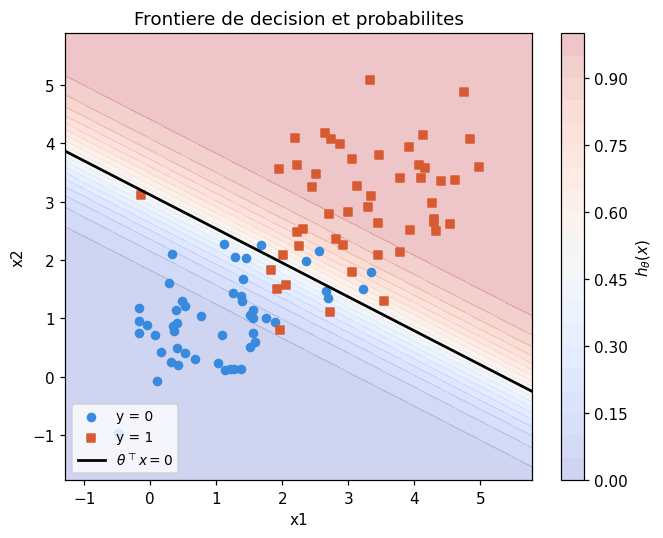

In [24]:
theta_ga, hist_ga = gradient_ascent(X, y, alpha=0.01, n_iters=20000)

fig, ax = plt.subplots(figsize=(6.2, 5))
xs = np.linspace(X_raw[:, 0].min() - 0.8, X_raw[:, 0].max() + 0.8, 200)
ys = np.linspace(X_raw[:, 1].min() - 0.8, X_raw[:, 1].max() + 0.8, 200)
xx, yy = np.meshgrid(xs, ys)
P = sigmoid(ajoute_biais(np.c_[xx.ravel(), yy.ravel()]) @ theta_ga).reshape(xx.shape)
cf = ax.contourf(xx, yy, P, levels=np.linspace(0, 1, 21), cmap="coolwarm", alpha=0.25)
plt.colorbar(cf, ax=ax, label=r"$h_\theta(x)$")

ax.scatter(X_raw[y == 0, 0], X_raw[y == 0, 1], c="#378ADD", s=28, label="y = 0")
ax.scatter(X_raw[y == 1, 0], X_raw[y == 1, 1], c="#D85A30", s=28, marker="s", label="y = 1")
ax.plot(xs, frontiere(theta_ga, xs), "k-", lw=1.8, label=r"$\theta^\top x = 0$")

ax.set_xlim(xs.min(), xs.max()); ax.set_ylim(ys.min(), ys.max())
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(loc="lower left", fontsize=9)
ax.set_title("Frontiere de decision et probabilites")
plt.tight_layout(); plt.show()

Le dégradé matérialise $h_{\theta}(x)$. La frontière noire est la ligne des 50 %, et les
points mal classés sont ceux du mauvais côté — inévitables, puisque les nuages se
chevauchent. C'est l'**irreducible error** du point **BHD-18**.

Notez que la frontière est **droite**. Un modèle logistique sans transformation de features
ne peut produire qu'un hyperplan ; pour une frontière courbe il faudrait ajouter des termes
comme $x_{1}^{2}$ ou $x_{1}x_{2}$ (point **B12-5**).

---
## 8. La hessienne

$$H_{jk} = \frac{\partial^{2}\ell(\theta)}{\partial\theta_{j}\,\partial\theta_{k}}
\qquad\Longrightarrow\qquad
H = -X^{\top}\operatorname{diag}\bigl(h\odot(1-h)\bigr)X \;\in\; \mathbb{R}^{(d+1)\times(d+1)}$$

où $\odot$ est le produit terme à terme. La matrice $\operatorname{diag}(\cdot)$ porte sur sa
diagonale les $h^{(i)}(1-h^{(i)})$ — c'est-à-dire exactement $g'(z^{(i)})$, la dérivée de la
sigmoïde du trou 3.

$H$ est **définie négative**, ce qui dit que $\ell$ est concave : il n'y a qu'un seul maximum,
pas de minimum local où se piéger. C'est une propriété précieuse, que les réseaux de neurones
perdront.

### Trou 8

**Ne construisez pas la matrice diagonale $n \times n$.** Pour $n = 100$ elle tiendrait, mais
c'est l'habitude à ne pas prendre : à $n = 10^{5}$ elle pèserait 80 Go.

L'astuce est de multiplier ligne par ligne. Si `w` est le vecteur des poids,
`X.T * w` multiplie chaque **colonne** de `X.T` par le scalaire correspondant de `w`, ce qui
revient exactement à $X^{\top}\operatorname{diag}(w)$ pour un coût en $O(nd)$ au lieu de
$O(n^{2}d)$.

In [25]:
# TODO (trou 8) - Calculer la hessienne. Sortie : matrice (d+1, d+1).
#   Etapes : h = sigmoid(X @ theta), puis w = h*(1-h), puis -(X.T * w) @ X
#   N'oubliez pas le signe moins.

def hessienne(theta, X, y):
    h = sigmoid(X@theta)
    w=h*(1-h)
    return -( X.T * w ) @ X        # <-- a completer

In [26]:
# Verification - ne modifiez pas cette cellule : HESSIAN CHECK par differences finies
_rng = np.random.default_rng(1)
for _essai in range(3):
    _th = _rng.normal(0, 0.5, 3)
    _H = hessienne(_th, X, y)

    _Hnum = np.zeros((3, 3))
    for j in range(3):
        e = np.zeros(3); e[j] = 1e-6
        _Hnum[:, j] = (gradient(_th + e, X, y) - gradient(_th - e, X, y)) / 2e-6

    assert _H.shape == (3, 3), f"la hessienne doit etre (3, 3), pas {_H.shape}"
    assert np.allclose(_H, _H.T), "une hessienne est toujours symetrique"
    _err = np.linalg.norm(_H - _Hnum) / np.linalg.norm(_Hnum)
    assert _err < 1e-5, (
        f"desaccord avec les differences finies du gradient (erreur {_err:.2e}).\n"
        f"  signe oublie ? H doit etre NEGATIVE.")
    assert np.all(np.linalg.eigvalsh(_H) < 0), \
        "toutes les valeurs propres doivent etre < 0 (H definie negative)"

print("Trou 8 : OK  (hessienne validee par differences finies)")
print("valeurs propres en theta=0 :", np.linalg.eigvalsh(hessienne(np.zeros(3), X, y)).round(2))

Trou 8 : OK  (hessienne validee par differences finies)
valeurs propres en theta=0 : [-311.66  -12.49   -6.37]


---
## 9. Newton

$$\theta := \theta - H^{-1}\,\nabla_{\theta}\,\ell(\theta)$$

L'idée : au lieu de suivre la pente à l'aveugle, on approche $\ell$ **localement par une
parabole** (son développement de Taylor à l'ordre 2) et on saute directement au sommet de
cette parabole.

### Trou 9

**Ne calculez jamais $H^{-1}$ explicitement.** `np.linalg.solve(H, g)` résout $Hx = g$ par
factorisation LU : c'est environ deux fois plus rapide que `np.linalg.inv(H) @ g` et
numériquement bien plus stable. C'est une règle générale d'algèbre linéaire numérique —
inverser une matrice pour la multiplier ensuite est presque toujours une erreur.

In [37]:
H=hessienne(np.zeros(X.shape[1]), X, y)
H.shape[0]

3

In [38]:
# TODO (trou 9) - Completer la boucle de Newton.
#   A chaque iteration : gradient, hessienne, puis le pas.
#   Indice : np.linalg.solve(H, g) calcule H^{-1} g sans inverser H.
#   Attention au signe : la mise a jour est theta - H^{-1} grad.

def newton(X, y, n_iters=20, tol=1e-10):
    theta = np.zeros(X.shape[1])
    historique = [log_vraisemblance(theta, X, y)]

    for _ in range(n_iters):
        g = gradient(theta, X, y)                  # <-- a completer : gradient
        H = hessienne(theta, X, y)                  # <-- a completer : hessienne
        theta = theta - np.linalg.solve(H, g)            # <-- a completer : le pas de Newton
        historique.append(log_vraisemblance(theta, X, y))
        if np.max(np.abs(g)) < tol:
            break

    return theta, np.array(historique)

In [39]:
# Verification - ne modifiez pas cette cellule
try:
    _th_n, _hist_n = newton(X, y)
except np.linalg.LinAlgError:
    raise AssertionError(
        "la hessienne est devenue singuliere : theta a diverge.\n"
        "  H est DEJA negative, donc la mise a jour est theta - solve(H, g),\n"
        "  pas theta + solve(H, g)")

assert np.all(np.isfinite(_th_n)), "theta contient des inf ou des nan"
assert _hist_n[-1] > _hist_n[0], \
    "la vraisemblance a baisse : verifiez le signe (theta - H^{-1} g, et H deja negative)"
assert len(_hist_n) - 1 <= 15, \
    f"Newton devrait converger en moins de 15 iterations, pas {len(_hist_n)-1}"
assert np.max(np.abs(gradient(_th_n, X, y))) < 1e-6, "le gradient final n'est pas nul"

_th_g, _ = gradient_ascent(X, y, alpha=0.01, n_iters=50000)
assert np.allclose(_th_n, _th_g, atol=1e-4), (
    "Newton et gradient ascent doivent converger vers LE MEME theta.\n"
    f"  Newton   : {_th_n}\n  gradient : {_th_g}")
print(f"Trou 9 : OK   {len(_hist_n)-1} iterations")
print("theta =", _th_n.round(5))

Trou 9 : OK   9 iterations
theta = [-7.10962  1.32704  2.28291]


### La convergence quadratique, vue de près

In [41]:
theta_newton, hist_newton = newton(X, y)
lmax = hist_newton[-1]

print(f"{'iter':>5} {'l(theta)':>18} {'ecart au max':>15} {'-log10(ecart)':>15}")
for i, v in enumerate(hist_newton):
    e = lmax - v
    col = "exact" if e <= 0 else f"{-np.log10(e):.1f}"
    print(f"{i:>5} {v:18.10f} {e:15.3e} {col:>15}")

 iter           l(theta)    ecart au max   -log10(ecart)
    0     -69.3147180560       4.833e+01            -1.7
    1     -30.8675004664       9.880e+00            -1.0
    2     -23.6233595339       2.636e+00            -0.4
    3     -21.4373013056       4.494e-01             0.3
    4     -21.0137171573       2.586e-02             1.6
    5     -20.9879872905       1.318e-04             3.9
    6     -20.9878554843       3.946e-09             8.4
    7     -20.9878554804       0.000e+00           exact
    8     -20.9878554804       3.553e-15            14.4
    9     -20.9878554804       0.000e+00           exact


La dernière colonne compte les **décimales exactes** : une valeur de 3,9 signifie que l'écart
au maximum vaut $10^{-3,9}$. Les premières lignes sont négatives, l'écart y dépassant 1.

Lisez la progression en fin de parcours : $1{,}6 \to 3{,}9 \to 8{,}4$. Le nombre de décimales
exactes **double à chaque itération**. C'est la définition de la **convergence quadratique** :

$$\lVert\theta_{t+1} - \theta^{*}\rVert \;\leq\; c\,\lVert\theta_{t} - \theta^{*}\rVert^{2}$$

Le gradient ascent, lui, converge **linéairement** : il gagne un facteur constant par
itération, pas un carré. D'où l'écart de trois ordres de grandeur sur le nombre d'itérations.

---
## 10. Comparaison

*Cellules complètes.*

In [42]:
t0 = time.perf_counter(); theta_ga, hist_ga = gradient_ascent(X, y, alpha=0.01, n_iters=50000)
t_ga = time.perf_counter() - t0

t0 = time.perf_counter(); theta_nt, hist_nt = newton(X, y)
t_nt = time.perf_counter() - t0

print(f"{'methode':<18}{'iterations':>12}{'duree (ms)':>13}{'l(theta)':>16}")
print(f"{'gradient ascent':<18}{len(hist_ga)-1:>12}{t_ga*1000:>13.1f}{hist_ga[-1]:>16.8f}")
print(f"{'Newton':<18}{len(hist_nt)-1:>12}{t_nt*1000:>13.1f}{hist_nt[-1]:>16.8f}")
print(f"\necart maximal sur theta : {np.abs(theta_ga - theta_nt).max():.2e}")

methode             iterations   duree (ms)        l(theta)
gradient ascent           4608        197.5    -20.98785548
Newton                       9          0.9    -20.98785548

ecart maximal sur theta : 2.90e-07


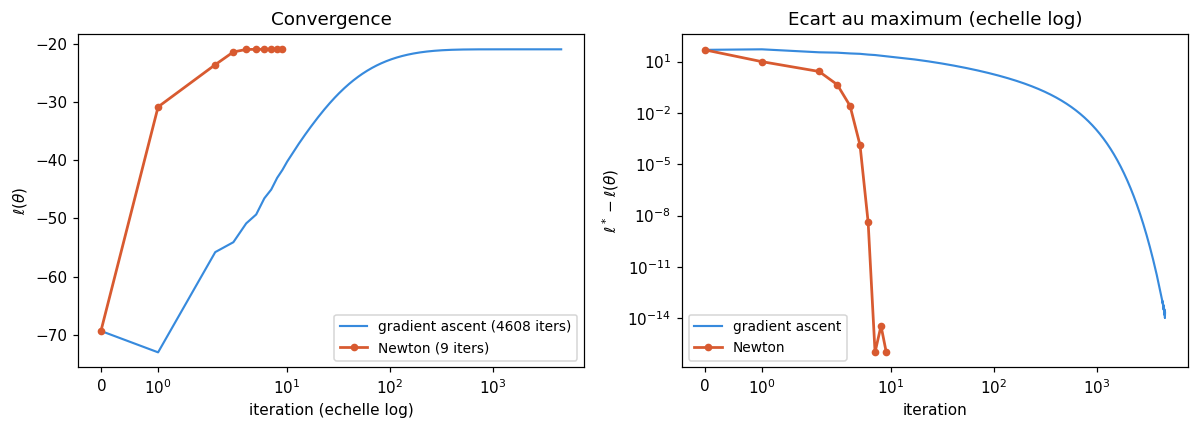

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.plot(hist_ga, color="#378ADD", lw=1.4, label=f"gradient ascent ({len(hist_ga)-1} iters)")
ax.plot(hist_nt, color="#D85A30", lw=1.8, marker="o", ms=4, label=f"Newton ({len(hist_nt)-1} iters)")
ax.set_xscale("symlog")
ax.set_xlabel("iteration (echelle log)"); ax.set_ylabel(r"$\ell(\theta)$")
ax.legend(fontsize=9); ax.set_title("Convergence")

ax = axes[1]
lmax = max(hist_ga[-1], hist_nt[-1])
ax.semilogy(np.maximum(lmax - hist_ga, 1e-16), color="#378ADD", lw=1.4, label="gradient ascent")
ax.semilogy(np.maximum(lmax - hist_nt, 1e-16), color="#D85A30", lw=1.8, marker="o", ms=4, label="Newton")
ax.set_xscale("symlog"); ax.set_xlabel("iteration"); ax.set_ylabel(r"$\ell^* - \ell(\theta)$")
ax.legend(fontsize=9); ax.set_title("Ecart au maximum (echelle log)")

plt.tight_layout(); plt.show()

### Pourquoi le gradient est si lent : le conditionnement

La vitesse du gradient ascent est gouvernée par le **conditionnement** de la hessienne, le
rapport entre sa plus grande et sa plus petite valeur propre :

$$\kappa = \frac{\lambda_{\max}}{\lambda_{\min}}$$

Géométriquement, $\kappa$ mesure l'allongement des courbes de niveau de $\ell$. Quand elles
forment des ellipses étirées, le gradient pointe perpendiculairement à la courbe de niveau,
donc **à côté** du sommet : la trajectoire zigzague.

Le gradient ascent converge en $O(\kappa \log(1/\varepsilon))$ itérations. Newton, en
multipliant par $H^{-1}$, **redresse** ces ellipses en cercles : sa vitesse ne dépend plus
de $\kappa$ du tout.

In [44]:
for nom, t in [("theta = 0", np.zeros(3)), ("theta optimal", theta_nt)]:
    ev = np.linalg.eigvalsh(-hessienne(t, X, y))
    print(f"{nom:16s} valeurs propres de -H : {ev.round(2)}   kappa = {ev.max()/ev.min():.0f}")

theta = 0        valeurs propres de -H : [  6.37  12.49 311.66]   kappa = 49
theta optimal    valeurs propres de -H : [ 0.34  4.11 59.57]   kappa = 174


### Le pas d'apprentissage

Newton n'a **aucun hyperparamètre**. Le gradient ascent en a un, et il est critique. La
théorie donne une borne de stabilité :

$$\alpha < \frac{2}{L} \qquad\text{où } L = \lambda_{\max}(-H)$$

Vérifions-la.

In [45]:
L = np.linalg.eigvalsh(-hessienne(np.zeros(3), X, y)).max()
print(f"L = {L:.1f}  ->  borne theorique alpha < 2/L = {2/L:.5f}\n")

print(f"{'alpha':>9}{'iterations':>12}{'l final':>15}{'1er pas':>12}")
for a in [0.3, 0.1, 0.03, 0.01, 0.005, 0.001]:
    th, h = gradient_ascent(X, y, alpha=a, n_iters=200000)
    n_it = len(h) - 1
    etat = "DIVERGE" if not np.isfinite(h[-1]) or h[-1] < -1e3 else (
        "trop lent" if n_it >= 199999 else f"{n_it}")
    premier = "baisse" if h[1] < h[0] else "monte"
    print(f"{a:9.4f}{etat:>12}{h[-1]:15.6f}{premier:>12}")

L = 311.7  ->  borne theorique alpha < 2/L = 0.00642

    alpha  iterations        l final     1er pas
   0.3000   trop lent    -135.069982      baisse
   0.1000   trop lent     -48.604808      baisse
   0.0300        1465     -20.987855      baisse
   0.0100        4608     -20.987855      baisse
   0.0050        9225     -20.987855       monte
   0.0010       46156     -20.987855       monte


La prédiction se vérifie exactement : **au-dessus de $2/L \approx 0{,}0064$, le premier pas
fait baisser $\ell$** ; en dessous, il la fait monter. Et trop grand, l'algorithme oscille
sans jamais converger.

Notez pourtant que $\alpha = 0{,}03$, qui viole la borne, converge **plus vite** que
$\alpha = 0{,}005$ qui la respecte. La borne est calculée en $\theta = 0$ ; $L$ diminue à
mesure que $\theta$ s'éloigne, donc un pas initialement trop grand redevient admissible.
C'est ce qui justifie les **learning rate schedules** du point **B11-6**.

### Newton vu comme un gradient ascent intelligent

Mettez les deux mises à jour côte à côte :

$$\theta := \theta + \underbrace{\alpha}_{\text{scalaire, choisi à la main}} \nabla\ell
\qquad\qquad
\theta := \theta + \underbrace{\left(-H^{-1}\right)}_{\text{matrice, calculée}} \nabla\ell$$

Newton remplace le pas scalaire par une **matrice**, qui adapte la longueur du pas
*direction par direction*. Là où la courbure est forte, il avance peu ; là où elle est
faible, il avance beaucoup. C'est pour cela qu'il n'a rien à régler.

---
## 11. Les deux pièges

### Le coût cubique

Chaque itération de Newton inverse une matrice $(d+1) \times (d+1)$, ce qui coûte
$O(d^{3})$. Pour $d = 2$, gratuit. Pour $d = 10^{4}$ — ce qui est banal en traitement de
texte ou d'image — chaque itération demande $10^{12}$ opérations.

**Verdict** : Newton pour $d$ petit (quelques dizaines à quelques centaines de features),
gradient stochastique pour $d$ grand. C'est exactement ce que fait scikit-learn, dont le
solveur `lbfgs` par défaut est un compromis : il approche $H^{-1}$ sans jamais la construire.

In [46]:
for d in [10, 100, 1_000, 10_000]:
    print(f"d = {d:6d}  ->  d^3 = {d**3:.1e} operations par iteration de Newton")

d =     10  ->  d^3 = 1.0e+03 operations par iteration de Newton
d =    100  ->  d^3 = 1.0e+06 operations par iteration de Newton
d =   1000  ->  d^3 = 1.0e+09 operations par iteration de Newton
d =  10000  ->  d^3 = 1.0e+12 operations par iteration de Newton


### La séparation parfaite

Reprenons le point soulevé à la section 2. Si les deux classes sont **parfaitement
séparables**, le maximum de vraisemblance **n'existe pas** : pour tout $\theta$ qui sépare
correctement, $2\theta$ fait mieux, $10\theta$ encore mieux. L'algorithme pousse
$\lVert\theta\rVert$ vers l'infini.

Observons.

In [47]:
rng_sep = np.random.default_rng(0)
Xs_raw = np.vstack([rng_sep.normal([0, 0], 0.4, (40, 2)),
                    rng_sep.normal([5, 5], 0.4, (40, 2))])
ys = np.concatenate([np.zeros(40), np.ones(40)])
Xs = ajoute_biais(Xs_raw)

th_s, hist_s = newton(Xs, ys, n_iters=12)
print(f"{'iter':>5}{'||theta||':>14}{'l(theta)':>16}")
for k in range(1, 13):
    t, h = newton(Xs, ys, n_iters=k)
    print(f"{k:>5}{np.linalg.norm(t):14.2f}{h[-1]:16.3e}")

 iter     ||theta||        l(theta)
    1          2.09      -1.064e+01
    2          3.31      -3.664e+00
    3          4.46      -1.338e+00
    4          5.59      -4.980e-01
    5          6.72      -1.866e-01
    6          7.88      -7.007e-02
    7          9.05      -2.634e-02
    8         10.23      -9.900e-03
    9         11.44      -3.719e-03
   10         12.66      -1.396e-03
   11         13.90      -5.232e-04
   12         15.16      -1.959e-04


$\lVert\theta\rVert$ explose, $\ell(\theta)$ tend vers 0 par en dessous — son supremum, jamais
atteint. En pratique la hessienne devient singulière et `np.linalg.solve` finit par échouer
ou renvoyer n'importe quoi.

**Les deux parades**, toutes deux au programme du bloc **B13** :

- la **régularisation** $L_{2}$, qui ajoute $-\tfrac{\lambda}{2}\lVert\theta\rVert^{2}$ à
  $\ell$ et rend le maximum fini ;
- un **nombre d'itérations maximal**, qui est de l'early stopping déguisé.

C'est pourquoi `LogisticRegression` de scikit-learn est régularisée **par défaut**
(`C=1.0`) : sans cela, elle planterait sur tout jeu séparable.

---
## 12. Validation croisée avec scikit-learn

Dernière vérification : votre implémentation doit retrouver celle de la bibliothèque. On
désactive la régularisation pour comparer ce qui est comparable.

*Cellule complète.*

In [48]:
from sklearn.linear_model import LogisticRegression

# C est l'INVERSE de la force de regularisation : C = inf la desactive.
skl = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=2000)
skl.fit(X_raw, y)
theta_skl = np.concatenate([skl.intercept_, skl.coef_[0]])

print("votre Newton   :", theta_newton.round(5))
print("scikit-learn   :", theta_skl.round(5))
print(f"\necart maximal  : {np.abs(theta_newton - theta_skl).max():.2e}")
print(f"l(theta) vous  : {log_vraisemblance(theta_newton, X, y):.8f}")
print(f"l(theta) skl   : {log_vraisemblance(theta_skl, X, y):.8f}")

votre Newton   : [-7.10962  1.32704  2.28291]
scikit-learn   : [-7.11041  1.32693  2.28342]

ecart maximal  : 7.90e-04
l(theta) vous  : -20.98785548
l(theta) skl   : -20.98785586


---
## 13. Bilan

### Ce qu'il faut retenir

| | gradient ascent | Newton |
|---|---|---|
| mise à jour | $\theta + \alpha\nabla\ell$ | $\theta - H^{-1}\nabla\ell$ |
| convergence | linéaire | **quadratique** |
| itérations ici | ~4 600 | **~7** |
| coût par itération | $O(nd)$ | $O(nd^{2} + d^{3})$ |
| hyperparamètre | $\alpha$, critique | **aucun** |
| sensible au conditionnement | oui, en $O(\kappa)$ | non |
| passe à l'échelle en $d$ | oui | non |

### Les réflexes à emporter

**Vérifiez toute dérivée écrite à la main** par différences finies centrées. Trois lignes de
code, et vous ne chercherez plus jamais un signe inversé pendant une heure.

**N'inversez jamais une matrice pour la multiplier.** `solve(H, g)`, pas `inv(H) @ g`.

**Ne construisez pas de matrice diagonale $n \times n$.** Multipliez ligne par ligne.

**Méfiez-vous de `log` et de `exp` nus.** `logaddexp` et la sigmoïde par branches existent
pour une raison.

### Auto-évaluation

Sans rouvrir le notebook :

1. Pourquoi le gradient de $\ell$ a-t-il la même forme que celui de la régression linéaire,
   alors que $h_{\theta}$ n'est plus linéaire ?
2. Que signifie « $H$ est définie négative », et quelle propriété de $\ell$ cela traduit-il ?
3. Pourquoi Newton n'a-t-il pas de learning rate ?
4. Dans quel régime de $d$ faut-il préférer le gradient stochastique, et pourquoi ?
5. Que se passe-t-il si les deux classes sont parfaitement séparables, et comment y remédier ?
6. Pourquoi écrit-on `np.linalg.solve(H, g)` plutôt que `np.linalg.inv(H) @ g` ?

### Rattachement au carnet

- **B11-2** : convention d'intercept, colonne de 1.
- **B11-6** : learning rate et schedules.
- **B14-2** à **B14-4** : sigmoïde, maximum de vraisemblance, gradient.
- **B14-5** : frontière de décision $\theta^{\top}x = 0$.
- **B14-8** : Newton, hessienne, convergence quadratique.
- **B12-5** : frontière linéaire et transformations de features.
- **B13** : régularisation $L_{2}$ face à la séparation parfaite.
- **B15** : pourquoi la forme du gradient se répète — modèles linéaires généralisés.

### Suite

Le bloc **B15** montre que la sigmoïde, le softmax et la régression linéaire sortent tous de
la même famille exponentielle, et que la forme *erreur $\times$ feature* du gradient en est
une conséquence directe, pas une coïncidence.